# Xenium 5K colitis — communication niches

选择 **cccphe**，执行 **Restart Kernel → Run All**。读取已下载的健康（HC）、溃疡性结肠炎（UC）和免疫治疗相关结肠炎（ICI）数据；本次复用第32轮最佳权重，仅执行推理、聚类与出图，不追加训练；完整结果存在时直接复用。所有矩阵、模型及高清 PNG/PDF/SVG 保存到 NAS。

用原始计数构建 CCC，逐组织片段建图；GNN 只输入表达和空间关系，学习32个非负程序。目标为 **CCC 重构＋0.005×程序正则**，NMF 初始化；不训练组成或基因表达分支。全部9位患者、35个保留组织片段的所有微环境共同参与训练，不留出独立测试集。固定训练子集只用于观察训练内重构曲线和无监督K选择，不称为独立验证。疾病分组不进入编码器、损失或K选择。Niche 基于相对程序组成，并保留较低权重的总体通讯强度，以减轻检测深度差异的影响。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,contextlib,json
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from IPython.display import display
set_matplotlib_formats('retina')
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.cohorts.colitis import run
from phenoniche.cohorts.colitis_reporting import ColitisReport
CONFIG=ROOT/'config/colitis_5k.json'
OUTPUT=Path(json.loads(CONFIG.read_text())['output_dir'])
OUTPUT.mkdir(parents=True,exist_ok=True)
with (OUTPUT/'notebook_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    run(CONFIG,postprocess_only=True)
report=ColitisReport(OUTPUT)
def show(fig):
    display(fig);plt.close(fig)
display(report.overview())

,Dataset and model
Patients,9
Cells,260177
Genes,4737
Cell types,13
Tissue fragments,35
Panel-measurable LR pairs,2412
Retained LR pairs,286
Effective CCC features,1469
Encoder genes,2048
Communication programs,32


## 1. 空间组织与 communication niches

依次展示 HC、UC、ICI 三组的全部9位患者。每张图三列分别对应该组的3位患者，展示每位患者的全部保留片段，各不相连片段仅在图上平移紧凑排列，并标注F编号；保留每个片段内部的原始形状、距离和微米尺度，模型使用的坐标不变。上排是作者细胞类型，下排是相同细胞的 niche，形状与坐标严格一致；标题列出细胞数与片段数。

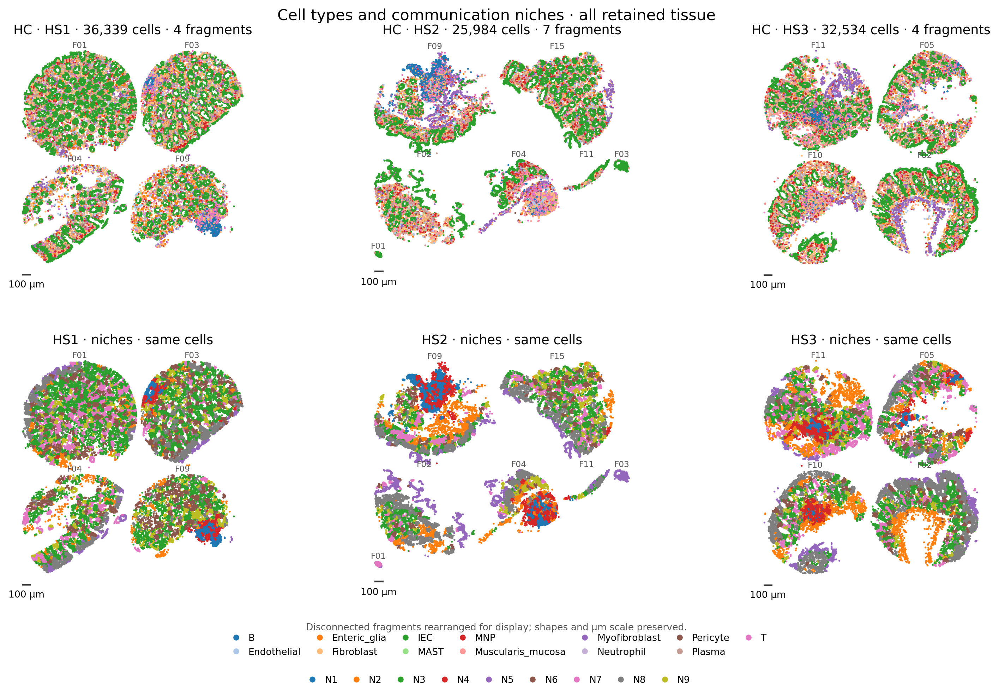

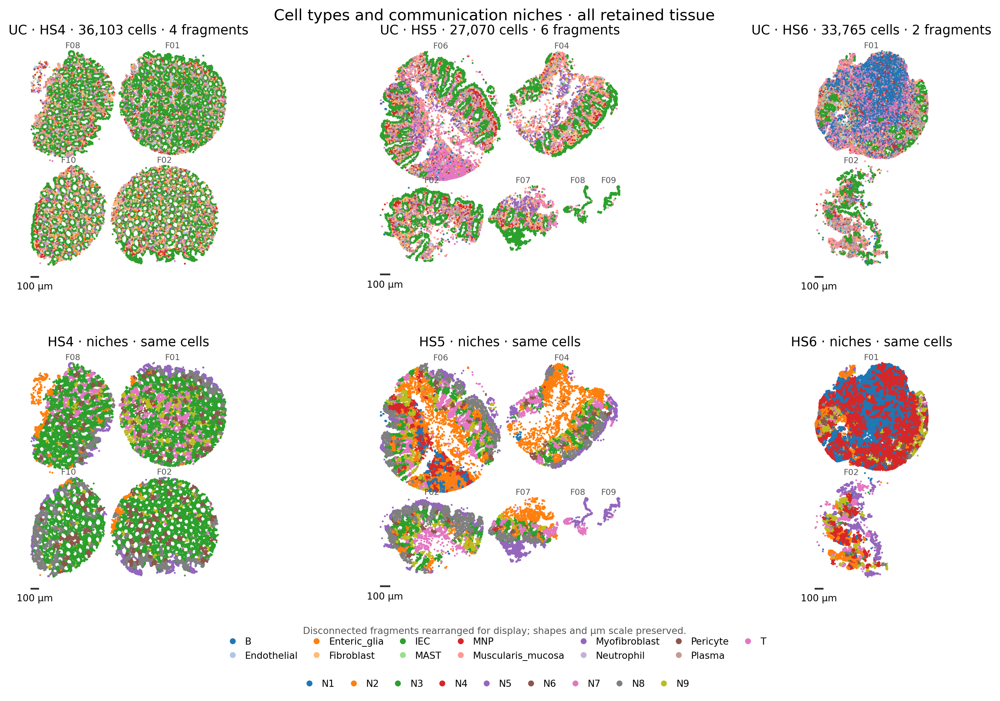

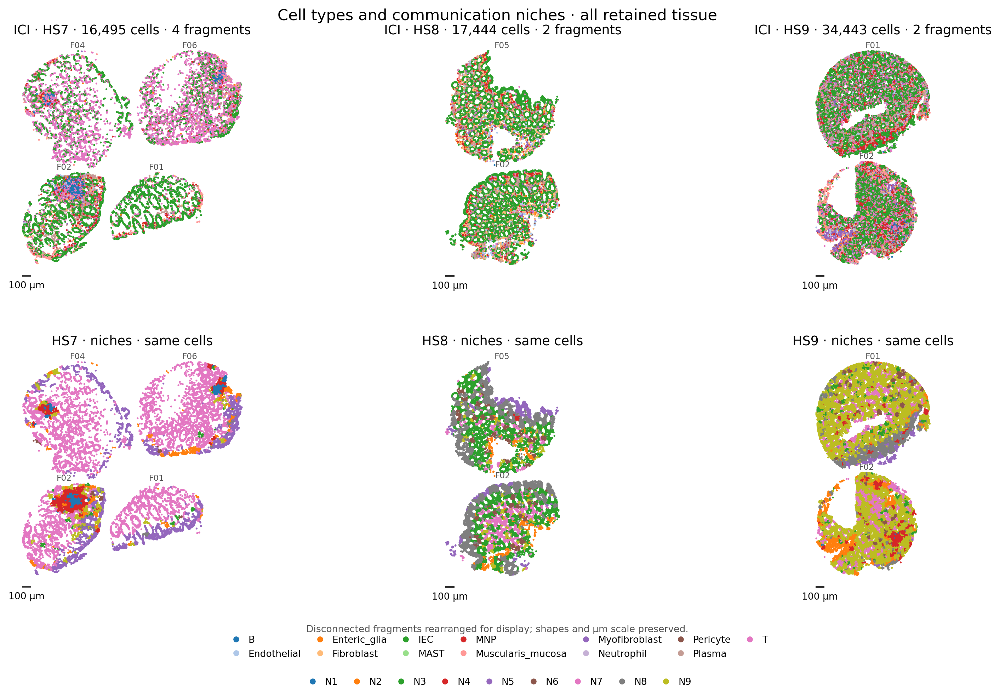

In [2]:
for condition in ('HC','UC','ICI'):
    show(report.spatial(condition))

## 2. 哪些 niche 在疾病中富集？

热图显示全部9位患者；每个点是一位患者，横线为组均值。九位患者的全部组织片段均参与联合发现，所有空间图已在上一节完整展示。丰度以患者为单位，三组各3位；这里展示组间模式，不做细胞数放大的显著性检验。

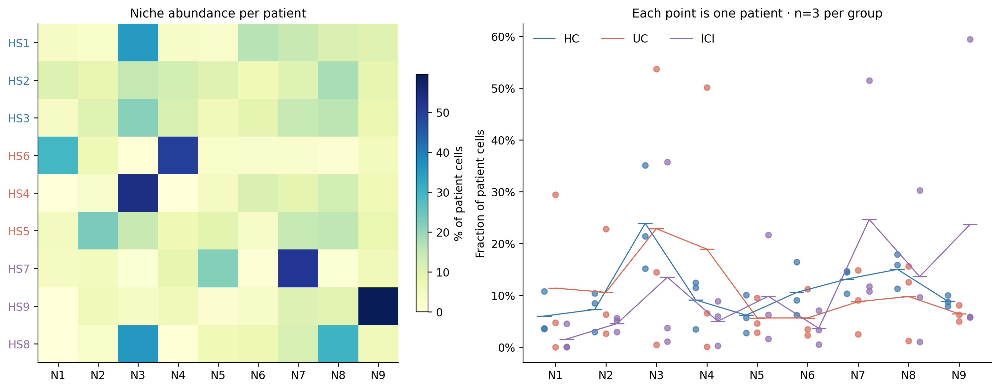

In [3]:
show(report.groups())

## 3. Niche 的通讯程序与细胞类型组成

左侧是 niche × program 活性，按列标准化以便比较；右侧用同一物理细胞对的空间权重汇总细胞组成，仅作解释，不作为模型辅助损失。

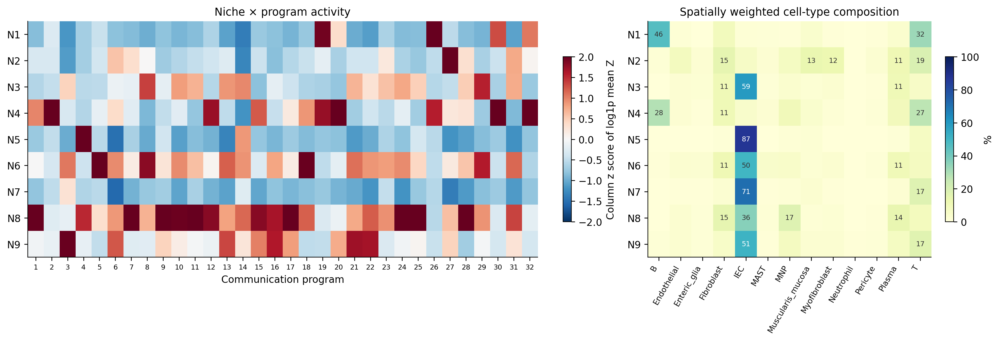

In [4]:
show(report.niche_heatmaps())

## 4. 32个通讯程序学到了什么？

左侧显示程序平均活性占比，右侧展示非负字典 H 的代表性 sender→receiver→LR。H 的颜色按各程序最大 loading 缩放；原始 H 和完整排名另存 NAS。

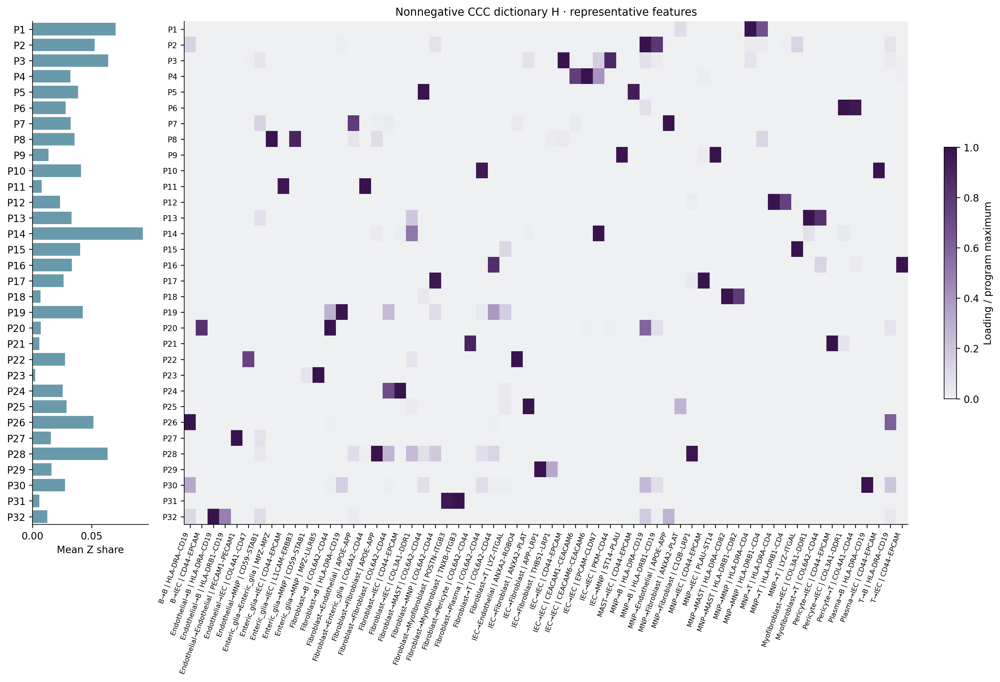

In [5]:
show(report.dictionary())

## 5. 疾病相关程序的空间位置与代表性 CCC

选择患者平均活性相对 HC 增加最多的 UC、ICI 程序用于训练后解释；每组展示细胞数最多患者的全部片段，标题标注患者；同一行三组共用颜色尺度。下表显示丰度至少3%、相对 HC 最富集的 UC/ICI niche 的 top10 CCC；所有 niche 的完整 top10 表在 NAS。富集表示描述性关联，不能解释为实验验证的通讯因果。

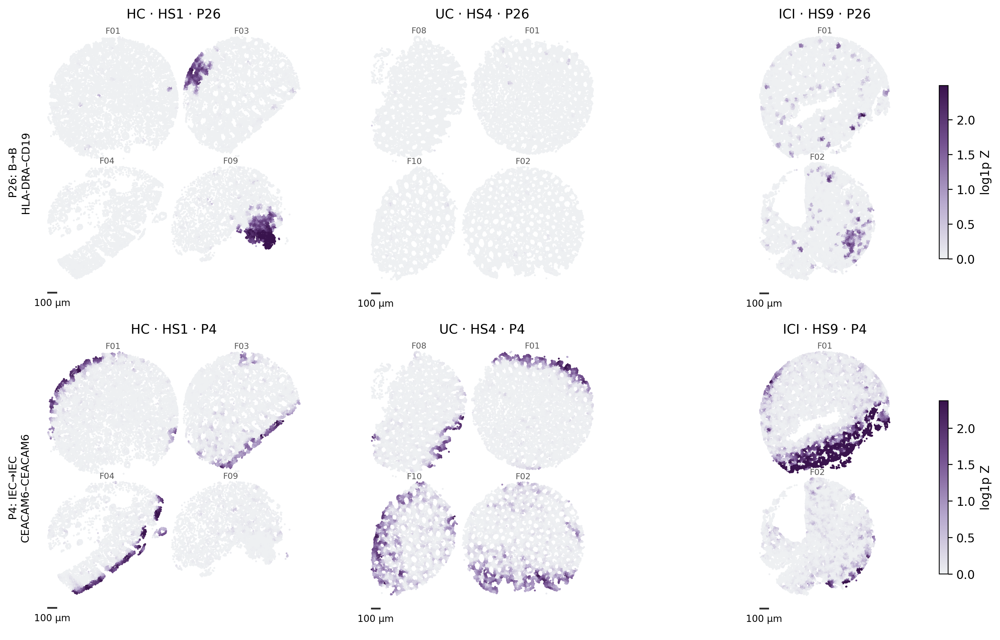

,niche,rank,sender,receiver,LR,mean_reconstructed_CCC,main_program
30,4,1,MNP,B,HLA-DRA–CD19,1.070,2
31,4,2,MNP,B,HLA-DRB1–CD19,0.790,2
32,4,3,B,B,HLA-DRA–CD19,0.706,26
33,4,4,MNP,T,LYZ–ITGAL,0.690,15
34,4,5,B,MNP,HLA-DRA–CD4,0.413,2
35,4,6,T,B,HLA-DRA–CD19,0.406,26
36,4,7,B,B,HLA-DRB1–CD19,0.390,26
37,4,8,MNP,MNP,HLA-DRA–CD4,0.363,1
38,4,9,Fibroblast,B,HLA-DRA–CD19,0.326,19
39,4,10,MNP,T,HLA-DRA–CD4,0.315,12


All niche top10 CCC: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/colitis_xenium_5k_all_tissue/niche_top10_CCC.csv


In [6]:
show(report.program_spatial())
display(report.representative_ccc())
print("All niche top10 CCC:",OUTPUT/"niche_top10_CCC.csv")

## 6. 训练与重构

左：全体微环境的训练 CCC loss 与固定训练子集的监测 loss（评估模式、无梯度），虚线为选中 checkpoint；监测子集也参与训练。中：K=4–15 的队列内无监督选择；右：全队列抽样微环境的观测与重构 CCC。当前目标是联合发现，不输出独立测试性能；K选择不使用疾病标签。

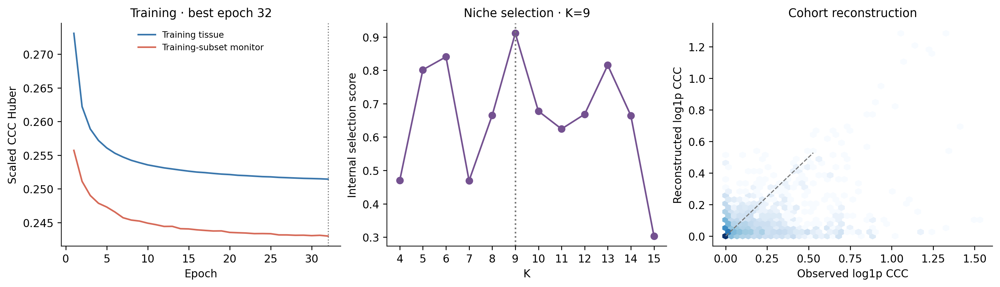

All model results and figures: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/colitis_xenium_5k_all_tissue


In [7]:
show(report.training())
print("All model results and figures:",OUTPUT)